# EDGE Quantum Guard (EQG) — QAOA robusto de 15 s: con EQG vs. sin EQG

## 1. Objetivo


**Replica con orden invertido (A→B).** Mismo EQG completo y misma carga que la corrida de referencia B→A; solo se invierte el orden de los brazos para controlar la deriva temporal del hardware.

Ejecutar **la misma carga QAOA** (MaxCut, cadena de 8 qubits, p=2) durante **~15 s de cuenta QPU por brazo**, primero **solo QAOA** (sin EQG) y despues con **EQG completo**, y evaluar la **estabilidad de la instancia (backend) y de cada qubit** *durante* y *despues* de la ejecucion.

```text
PRE (snapshot) -> BRAZO A: QAOA solo (~15 s) -> MID (snapshot) -> BRAZO B: EQG ON (~15 s) -> POST (snapshot)
```

## 2. Diseno (por que es robusto)

| Elemento | Decision |
|----------|----------|
| Carga | QAOA p=2 sobre MaxCut de camino de 8 nodos (nativo en heavy-hex: 0 SWAP si el layout es un camino fisico). Parametros optimos precalculados offline (numpy, sin gasto QPU) |
| Presupuesto | 15.0 s de cuenta QPU por brazo (tope duro con tolerancia). El plan (jobs, lotes, shots) se **dimensiona solo** a partir del presupuesto y del overhead por job y es **identico** en A y B |
| Tiempo | Dentro de cada job se intercalan *snapshots* de estabilidad entre lotes QAOA (sin pagar overhead extra por snapshot). EQG reacciona **entre jobs** |
| Snapshot por qubit | Ramsey (cuadraturas X/Y) + supervivencia de \|1> + error de lectura \|0> (solo en snapshots completos) |
| Instancia | Estado del backend (operativo, cola), sello de calibracion, T1/T2/lectura de los qubits del layout, proxy agregado |
| Despues de ejecutar | Snapshots PRE / MID / POST **simultaneos** para layout MORPH (con y sin DD) y layout ingenuo: separan deriva del hardware de efecto de EQG |
| Estadistica | Errores estandar por shots, pendientes OLS con SE, veredicto con umbral 2 sigma |

## 3. Roles de EQG (todos presentes)

| Rol | Nombre | Funcion |
|-----|--------|---------|
| Ojos | AOM / salud | Friccion, regimen, salud por qubit (calibracion + medida) |
| Reflejos | MORPH | Mejor camino fisico conectado (salud de qubits + error CZ) |
| Juicio | Plan de minima accion + causal | DD condicional, remap, abortar; veredicto causal |
| Manos | DD (CPMG/XY4) + ejecucion | Inserta DD en ventanas ociosas y ejecuta |

## 4. Criterios de aceptacion

| ID | Criterio |
|----|----------|
| C1 | B ejecuta Ojos, Reflejos, Juicio, Manos, QAOA, snapshots y Juicio causal |
| C2 | Cuenta QPU de B <= 15.0 s (+10 % tol.) |
| C3 | Cuenta QPU de A <= 15.0 s (+10 % tol.) y plan identico al de B |
| C4 | Serie de AR del QAOA y serie de estabilidad en ambos brazos |
| C5 | Snapshots PRE/MID/POST completos |
| C6 | Tabla de estabilidad por qubit (durante) y deriva PRE->MID->POST (despues) |
| C7 | Veredicto con estadistica (2 sigma), o "sin distincion" documentada |

**Cola no es cuenta.** Un solo experimento en hardware no prueba causalidad: el notebook reporta el efecto *con su incertidumbre*.


In [22]:
from kaggle_secrets import UserSecretsClient
t = UserSecretsClient().get_secret("IBM_QUANTUM_TOKEN")
print("token ok, len =", len(t.strip()) if t else 0)

token ok, len = 44


In [23]:
%pip install -q "qiskit>=1.0" "qiskit-ibm-runtime>=0.30" "qiskit-aer>=0.14" matplotlib scipy numpy

import os, time, json, heapq, uuid, math, warnings
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Sequence, Any
from dataclasses import dataclass, asdict, field
from enum import Enum
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)

# ============================================================
# PRE-REGISTRO — no modificar tras ver resultados
# ============================================================
MODE = "hardware"          # "sim" (ensayo FakeFez/Aer) | "hardware"
BACKEND_NAME = "ibm_fez"
SEED = 7

# --- Presupuesto QPU (cuenta IBM) ---
BUDGET_ARM_S = 15.0         # cuenta QPU por brazo
BUDGET_TOL = 1.10          # tolerancia de aceptacion (C2/C3)
N_JOBS_ARM = None          # None = auto: 3 jobs si el overhead medido <= 1.1 s, si no 2
CHUNKS_PER_JOB = 2         # lotes QAOA por job (cada uno seguido de un snapshot)
OVERHEAD_S = 2.0           # overhead por job (se recalibra con el job PRE si hay uso real)
T_SHOT_S = 331.6e-6        # tiempo conservador por shot (rep_delay + circuito + lectura)
SAFETY = 0.93              # margen al dimensionar el plan
JOB_TIMEOUT_S = 1800       # incluye cola

# --- Carga QAOA (MaxCut sobre un camino de N nodos) ---
N_QAOA = 8
P_LAYERS = 2
N_RESTARTS = 40

# --- Snapshots de estabilidad ---
SHOTS_SNAP_LIGHT = 96      # en-job: X, Y, Z1  (3 circuitos)
SHOTS_SNAP_FULL = 128      # PRE/MID/POST: X, Y, Z1, Z0 (4 circuitos)
PROBE_DELAY_US = 20.0      # espera libre fija de los probes
DD_SEQUENCE = "CPMG"       # "CPMG" (X-X) | "XY4" (cae a CPMG si no hay Y nativo)

# --- Umbrales ---
HEALTH_STABLE, HEALTH_DEGRADED = 0.65, 0.45   # salud por calibracion
REL_THR = 0.85             # coherencia medida / esperada por calibracion: <REL_THR -> DD
FLAG_REL = 0.75            # qubit marcado si (s_rel + 2 SE) < FLAG_REL
TARGET_INTEGRITY = 0.35
REMAP_TOL = 0.05           # con un qubit defectuoso MEDIDO se acepta un camino alternativo hasta 0.05 peor en calibracion
EDGE_W = 8.0               # peso del error CZ en la puntuacion de camino MORPH
JIT_OK, JIT_BAD = 0.04, 0.08      # jitter en exceso sobre ruido de shots
DRIFT_OK, DRIFT_BAD = 0.05, 0.10  # deriva total admisible durante el brazo
Z_SIG = 2.0                # umbral de significancia (sigmas)

OUT = Path("/kaggle/working/eqg_qaoa_AB") if Path("/kaggle/working").exists() else Path("eqg_qaoa_AB")
OUT.mkdir(parents=True, exist_ok=True)
print("EQG-QAOA  MODE=%s  backend=%s  N=%d p=%d  presupuesto/brazo=%.1fs" % (MODE, BACKEND_NAME, N_QAOA, P_LAYERS, BUDGET_ARM_S))
print("Gasto QPU esperado total ~%.0f s  (2 brazos x %.0f s + 3 snapshots ~2.5 s c/u)" % (2 * BUDGET_ARM_S + 7.5, BUDGET_ARM_S))


Note: you may need to restart the kernel to use updated packages.
EQG-QAOA  MODE=hardware  backend=ibm_fez  N=8 p=2  presupuesto/brazo=15.0s
Gasto QPU esperado total ~38 s  (2 brazos x 15 s + 3 snapshots ~2.5 s c/u)


In [24]:
# ============================================================
# EQG COMPLETO — contratos
# ============================================================
class QubitEstado(str, Enum):
    ESTABLE = "estable"
    DEGRADADO = "degradado"
    INESTABLE = "inestable"

class LayoutRegime(str, Enum):
    ESTABLE = "ESTABLE"
    INESTABLE = "INESTABLE"
    CONFLICTO = "CONFLICTO"

class IntervencionTipo(str, Enum):
    NINGUNA = "ninguna"
    DD_CONDICIONAL = "dd_condicional"
    REMAP_MORPH = "remap_morph"
    ABORTAR = "abortar"

@dataclass
class LayoutHealth:
    event_id: str
    backend: str
    candidates: List[int]
    qubits: Dict[int, dict]
    friction: float
    smoothed: float
    regime: str
    n_estable: int
    n_degradado: int
    n_inestable: int
    health_mean: float
    rel_mean: Optional[float] = None
    flagged: List[int] = field(default_factory=list)

@dataclass
class MorphLayout:
    event_id: str
    selected: List[int]
    score: float
    latency_ms: float
    connected: bool = True

@dataclass
class InterventionPlan:
    event_id: str
    tipo: str
    layout: List[int]
    activate_dd: bool
    reason: str
    expected_gain: float
    cost: float

@dataclass
class CausalVerdict:
    plan_id: str
    delta_friction: float
    delta_health: float
    root_cause: bool
    role: str
    success: bool
    notes: str

print("Contratos EQG OK")


Contratos EQG OK


In [25]:
# ============================================================
# OJOS — membrana AOM + salud (calibracion y medida)
# ============================================================
def _try(fn, default=None):
    try:
        v = fn()
        return default if v is None else v
    except Exception:
        return default

def cal_health(t1_us, t2_us, ro):
    t1 = t1_us if t1_us else 100.0
    t2 = t2_us if t2_us else 80.0
    ro = ro if ro is not None else 0.03
    h = 0.35 * min(t1 / 200.0, 1.0) + 0.35 * min(t2 / 150.0, 1.0) + 0.30 * (1.0 - min(ro / 0.08, 1.0))
    return float(np.clip(h, 0.02, 1.0))

def estado_from_h(h):
    if h >= HEALTH_STABLE: return QubitEstado.ESTABLE.value
    if h >= HEALTH_DEGRADED: return QubitEstado.DEGRADADO.value
    return QubitEstado.INESTABLE.value

def read_cal(backend, qs, refresh=False):
    """T1/T2 (us) y error de lectura por qubit + sello de calibracion de la instancia."""
    props = None
    try:
        props = backend.properties(refresh=True) if refresh else backend.properties()
    except Exception:
        props = _try(lambda: backend.properties())
    tgt = getattr(backend, "target", None)
    out = {}
    for q in qs:
        t1 = _try(lambda: props.t1(q)) if props is not None else None
        t2 = _try(lambda: props.t2(q)) if props is not None else None
        ro = _try(lambda: props.readout_error(q)) if props is not None else None
        if (t1 is None or t2 is None) and tgt is not None:
            qp = _try(lambda: tgt.qubit_properties[q])
            if qp is not None:
                t1 = t1 if t1 is not None else getattr(qp, "t1", None)
                t2 = t2 if t2 is not None else getattr(qp, "t2", None)
        if ro is None and tgt is not None:
            ro = _try(lambda: tgt["measure"][(q,)].error)
        out[int(q)] = {"t1_us": None if t1 is None else float(t1) * 1e6,
                       "t2_us": None if t2 is None else float(t2) * 1e6,
                       "ro": None if ro is None else float(ro)}
    stamp = _try(lambda: str(props.last_update_date), "desconocido") if props is not None else "desconocido"
    return out, stamp

def read_edge_err(backend):
    err = {}
    tgt = getattr(backend, "target", None)
    if tgt is None: return err
    for gname in ("cz", "ecr", "cx"):
        if gname in tgt.operation_names:
            for qargs, inst in tgt[gname].items():
                if inst is not None and getattr(inst, "error", None) is not None and len(qargs) == 2:
                    err[frozenset((int(qargs[0]), int(qargs[1])))] = float(inst.error)
            if err: break
    return err

def coupling_edges(backend):
    edges = []
    try:
        cm = backend.coupling_map
        if cm is not None:
            edges = [(int(a), int(b)) for a, b in cm.get_edges()]
    except Exception:
        pass
    if not edges:
        n = min(getattr(backend, "num_qubits", 16), 16)
        edges = [(i, i + 1) for i in range(n - 1)]
    return edges

def instance_status(backend):
    st = _try(lambda: backend.status())
    if st is None: return {}
    return {"operational": getattr(st, "operational", None), "pending_jobs": getattr(st, "pending_jobs", None),
            "status_msg": getattr(st, "status_msg", None), "t_unix": time.time()}


class AOMMembrane:
    def __init__(self, capacity=4, lo=0.25, hi=0.45):
        self.buf, self.cap, self.lo, self.hi = [], capacity, lo, hi
        self.regime = LayoutRegime.ESTABLE

    def push(self, friction: float):
        self.buf.append(friction)
        self.buf = self.buf[-self.cap:]
        sm = friction if len(self.buf) == 1 else 0.6 * friction + 0.4 * (sum(self.buf[:-1]) / (len(self.buf) - 1))
        r = self.regime
        if r == LayoutRegime.ESTABLE:
            if sm >= 0.70: self.regime = LayoutRegime.CONFLICTO
            elif sm >= self.hi: self.regime = LayoutRegime.INESTABLE
        elif r == LayoutRegime.INESTABLE:
            if sm < self.lo: self.regime = LayoutRegime.ESTABLE
            elif sm >= 0.70: self.regime = LayoutRegime.CONFLICTO
        else:
            if sm < self.lo: self.regime = LayoutRegime.ESTABLE
            elif sm < self.hi: self.regime = LayoutRegime.INESTABLE
        return self.regime, sm


class Ojos:
    def __init__(self):
        self.membrane = AOMMembrane()
        self.last = None

    def observe(self, backend_name, qubits, hm: Dict[int, float], rel_mean=None, flagged=None) -> LayoutHealth:
        qs = [int(q) for q in qubits]
        raw = float(np.mean([1.0 - hm[q] for q in qs])) if qs else 1.0
        if rel_mean is not None:
            raw = 1.0 - float(np.clip(rel_mean, 0.0, 1.0))
        regime, sm = self.membrane.push(raw)
        est = [estado_from_h(hm[q]) for q in qs]
        lh = LayoutHealth(
            event_id=str(uuid.uuid4()), backend=backend_name, candidates=qs,
            qubits={q: {"health": float(hm[q]), "estado": e} for q, e in zip(qs, est)},
            friction=raw, smoothed=sm, regime=regime.value,
            n_estable=est.count("estable"), n_degradado=est.count("degradado"), n_inestable=est.count("inestable"),
            health_mean=float(np.mean([hm[q] for q in qs])) if qs else 0.0,
            rel_mean=None if rel_mean is None else float(rel_mean), flagged=list(flagged or []))
        self.last = lh
        return lh

print("Ojos OK")


Ojos OK


In [26]:
# ============================================================
# REFLEJOS — MORPH: mejor camino fisico conectado de k qubits
# ============================================================
class Reflejos:
    def score_path(self, path, hm, edge_err):
        h = float(np.mean([hm[q] for q in path]))
        es = [edge_err.get(frozenset((a, b)), 0.01) for a, b in zip(path[:-1], path[1:])]
        return h - EDGE_W * (float(np.mean(es)) if es else 0.0)

    def select(self, hm: Dict[int, float], edges, edge_err, k: int, exclude=(), beam: int = 200) -> MorphLayout:
        t0 = time.perf_counter()
        excl = set(exclude)
        ok = {q for q, h in hm.items() if estado_from_h(h) != QubitEstado.INESTABLE.value and q not in excl}
        adj = {q: set() for q in ok}
        for a, b in edges:
            if a in ok and b in ok:
                adj[a].add(b); adj[b].add(a)
        frontier = [[q] for q in sorted(ok)]
        for _ in range(k - 1):
            nxt = [p + [n] for p in frontier for n in adj[p[-1]] if n not in p]
            if not nxt:
                frontier = []; break
            nxt.sort(key=lambda p: -self.score_path(p, hm, edge_err))
            frontier = nxt[:beam]
        if frontier:
            best = max(frontier, key=lambda p: self.score_path(p, hm, edge_err))
            return MorphLayout(str(uuid.uuid4()), list(best), self.score_path(best, hm, edge_err),
                               (time.perf_counter() - t0) * 1000, True)
        sel = [q for q, _ in sorted(((q, hm[q]) for q in ok), key=lambda x: -x[1])[:k]]
        return MorphLayout(str(uuid.uuid4()), sel, float(np.mean([hm[q] for q in sel])) if sel else 0.0,
                           (time.perf_counter() - t0) * 1000, False)

def layout_connected(layout, edges):
    es = {frozenset(e) for e in edges}
    return all(frozenset((a, b)) in es for a, b in zip(layout[:-1], layout[1:]))

print("Reflejos OK")


Reflejos OK


In [27]:
# ============================================================
# JUICIO — plan de minima accion + veredicto causal
# ============================================================
class Juicio:
    def planificar(self, lh: LayoutHealth, layout: List[int], alt: Optional[MorphLayout], cur_score: float) -> InterventionPlan:
        flagged = list(lh.flagged)
        need_dd = ((lh.rel_mean is not None and lh.rel_mean < REL_THR)
                   or (lh.n_degradado + lh.n_inestable) > 0 or lh.health_mean < HEALTH_STABLE or bool(flagged))
        remap = (bool(flagged) and alt is not None and alt.connected
                 and alt.score >= cur_score - REMAP_TOL and set(alt.selected) != set(layout))
        calm = (not need_dd) and (not flagged)
        opts = [dict(tipo=IntervencionTipo.NINGUNA, cost=0.0, gain=0.55 if calm else 0.0,
                     reason="regimen estable; no intervenir" if calm else "no intervenir")]
        if need_dd:
            opts.append(dict(tipo=IntervencionTipo.DD_CONDICIONAL, cost=0.25, gain=0.30 if flagged else 0.55,
                             reason="DD condicional por coherencia/salud" + ("; DD no basta con qubit defectuoso" if flagged else "")))
        if remap:
            opts.append(dict(tipo=IntervencionTipo.REMAP_MORPH, cost=0.40, gain=0.90,
                             reason="qubit(s) %s degradados; remap MORPH %s" % (flagged, alt.selected)))
        if lh.regime == "CONFLICTO" and lh.n_estable == 0:
            opts.append(dict(tipo=IntervencionTipo.ABORTAR, cost=0.0, gain=0.1, reason="CONFLICTO sin qubits estables"))
        elig = [o for o in opts if o["gain"] >= TARGET_INTEGRITY]
        ch = min(elig, key=lambda o: o["cost"]) if elig else max(opts, key=lambda o: o["gain"] / max(o["cost"], 0.01))
        t = ch["tipo"]
        return InterventionPlan(
            event_id=lh.event_id, tipo=t.value,
            layout=list(alt.selected) if t == IntervencionTipo.REMAP_MORPH else list(layout),
            activate_dd=(t in (IntervencionTipo.DD_CONDICIONAL, IntervencionTipo.REMAP_MORPH) and need_dd),
            reason=ch["reason"], expected_gain=ch["gain"], cost=ch["cost"])

    def evaluar(self, plan: InterventionPlan, before: LayoutHealth, after: LayoutHealth) -> CausalVerdict:
        df = before.smoothed - after.smoothed
        dh = after.health_mean - before.health_mean
        if dh > 0.03 or df > 0.03:
            return CausalVerdict(plan.event_id, df, dh, True, "causa_directa", True, "Mejora medible de estabilidad.")
        if plan.tipo == "ninguna" and before.regime == "ESTABLE" and after.regime == "ESTABLE":
            return CausalVerdict(plan.event_id, df, dh, True, "nulo", True, "Correcto no intervenir.")
        if abs(df) <= 0.03 and abs(dh) <= 0.03:
            return CausalVerdict(plan.event_id, df, dh, False, "nulo", True, "Estabilidad sostenida (sin cambio medible).")
        return CausalVerdict(plan.event_id, df, dh, False, "nulo", False, "Sin mejora medible; posible deterioro.")

print("Juicio OK")


Juicio OK


In [28]:
# ============================================================
# MANOS — DD real (CPMG/XY4) + snapshots de estabilidad por qubit
# ============================================================
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import XGate, YGate
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling

def resolve_dd_sequence(backend, name):
    if name == "XY4":
        ops = getattr(getattr(backend, "target", None), "operation_names", [])
        if "y" in ops:
            return "XY4", [XGate(), YGate(), XGate(), YGate()]
        print("[DD] XY4 no nativo en %s -> uso CPMG" % getattr(backend, "name", backend))
    return "CPMG", [XGate(), XGate()]

def _count_dd(tc):
    ops = tc.count_ops()
    return int(ops.get("x", 0) + ops.get("y", 0))

def apply_dd(tcs, backend, qubits, name=DD_SEQUENCE):
    """DD en ventanas ociosas de circuitos YA transpilados. Devuelve (circuitos, pulsos_insertados, secuencia)."""
    eff, seq = resolve_dd_sequence(backend, name)
    target = backend.target
    pm = PassManager([
        ALAPScheduleAnalysis(target=target),
        PadDynamicalDecoupling(target=target, dd_sequence=seq, qubits=[int(q) for q in qubits],
                               pulse_alignment=getattr(target, "pulse_alignment", 1), skip_reset_qubits=False)])
    out, added = [], 0
    for tc in tcs:
        try:
            tc2 = pm.run(tc)
        except Exception as e:
            print("[DD] ERROR al insertar DD (%s) -> circuito sin DD" % e)
            tc2 = tc
        added += _count_dd(tc2) - _count_dd(tc)
        out.append(tc2)
    return out, added, eff

def probe_delay(backend, us=PROBE_DELAY_US):
    dt = getattr(backend, "dt", None)
    if not dt:
        return float(us), "us"
    g = int(getattr(getattr(backend, "target", None), "granularity", 16) or 16)
    return max(g, int(round(us * 1e-6 / dt / g)) * g), "dt"

SNAP_KINDS_LIGHT = ["X", "Y", "Z1"]
SNAP_KINDS_FULL = ["X", "Y", "Z1", "Z0"]

def snap_circuits(n, delay, unit, full):
    """X/Y: Ramsey en cuadratura. Z1: supervivencia de |1>. Z0: error de lectura de |0>."""
    out = []
    for k in (SNAP_KINDS_FULL if full else SNAP_KINDS_LIGHT):
        qc = QuantumCircuit(n, n, name="snap_" + k)
        for i in range(n):
            if k in ("X", "Y"): qc.h(i)
            elif k == "Z1": qc.x(i)
        qc.barrier()
        for i in range(n): qc.delay(delay, i, unit=unit)
        qc.barrier()
        for i in range(n):
            if k == "Y": qc.sdg(i)
            if k in ("X", "Y"): qc.h(i)
        qc.measure(range(n), range(n))
        out.append(qc)
    return out

def bit_marginals(counts, n):
    """P(bit_b = 1) para cada clbit b (little-endian de Qiskit) y total de shots."""
    tot = sum(counts.values()) or 1
    m = np.zeros(n)
    for k, v in counts.items():
        s = str(k).replace(" ", "")
        if s.startswith("0x"): s = format(int(s, 16), "0%db" % n)
        s = s.zfill(n)[-n:][::-1]
        for b in range(n):
            if s[b] == "1": m[b] += v
    return m / tot, tot

def analyze_snap(cts: Dict[str, dict], layout: Sequence[int], cal: Dict[int, dict], delay_us: float = PROBE_DELAY_US) -> dict:
    """Estabilidad por qubit fisico a partir de un snapshot. Todo es lista (JSON-serializable)."""
    n = len(layout)
    pX, N = bit_marginals(cts["X"], n); pY, _ = bit_marginals(cts["Y"], n); p1, _ = bit_marginals(cts["Z1"], n)
    x, y = 1 - 2 * pX, 1 - 2 * pY
    coh = np.minimum(np.hypot(x, y), 1.0)
    sx = 2 * np.sqrt(np.clip(pX * (1 - pX), 1e-4, None) / N)
    sy = 2 * np.sqrt(np.clip(pY * (1 - pY), 1e-4, None) / N)
    se_coh = np.sqrt((x * sx) ** 2 + (y * sy) ** 2) / np.maximum(coh, 0.3)
    se_p1 = np.sqrt(np.clip(p1 * (1 - p1), 1e-4, None) / N)
    s = np.sqrt(np.clip(coh * p1, 1e-6, None))
    se_s = 0.5 * s * np.sqrt((se_coh / np.maximum(coh, 0.3)) ** 2 + (se_p1 / np.maximum(p1, 0.3)) ** 2)
    c = [cal.get(int(q), {}) for q in layout]
    t1 = np.array([(d.get("t1_us") or 100.0) for d in c]); t2 = np.array([(d.get("t2_us") or 80.0) for d in c])
    ro = np.array([(d.get("ro") if d.get("ro") is not None else 0.03) for d in c])
    exp_coh = np.exp(-delay_us / t2); exp_p1 = np.exp(-delay_us / t1) * (1 - ro); exp_s = np.sqrt(exp_coh * exp_p1)
    coh_rel, s_rel, se_rel = coh / exp_coh, s / exp_s, se_s / exp_s
    res = {"layout": [int(q) for q in layout], "shots": int(N),
           "coh": coh.tolist(), "p1": p1.tolist(), "s": s.tolist(), "se_s": se_s.tolist(),
           "coh_rel": coh_rel.tolist(), "s_rel": s_rel.tolist(), "se_rel": se_rel.tolist(),
           "mean_s": float(s.mean()), "se_mean_s": float(np.sqrt((se_s ** 2).sum()) / n),
           "mean_rel": float(s_rel.mean()), "se_mean_rel": float(np.sqrt((se_rel ** 2).sum()) / n),
           "mean_coh_rel": float(coh_rel.mean()),
           "flagged": [int(q) for q, a, e in zip(layout, s_rel, se_rel) if a + Z_SIG * e < FLAG_REL]}
    if "Z0" in cts:
        e0, _ = bit_marginals(cts["Z0"], n)
        res["e0"] = e0.tolist(); res["mean_e0"] = float(e0.mean())
        res["s_full"] = ((coh * p1 * (1 - e0)) ** (1 / 3)).tolist()
    return res

print("Manos OK  DD=%s  probe_delay=%.1fus" % (DD_SEQUENCE, PROBE_DELAY_US))


Manos OK  DD=CPMG  probe_delay=20.0us


In [29]:
# ============================================================
# CARGA QAOA — MaxCut en camino de N nodos (parametros optimos offline)
# ============================================================
from scipy.optimize import minimize

EDGES = [(i, i + 1) for i in range(N_QAOA - 1)]
WTS = [1.0] * len(EDGES)
_X = np.arange(2 ** N_QAOA)
BITS = ((_X[:, None] >> np.arange(N_QAOA)) & 1).astype(np.int8)     # bit i = qubit/clbit i

CV = np.zeros(2 ** N_QAOA)
for (i, j), w in zip(EDGES, WTS):
    CV += w * (BITS[:, i] != BITS[:, j])
C_OPT = float(CV.max())
OPT_SET = np.where(np.isclose(CV, C_OPT))[0]

def _mixer(psi, b, n):
    c, s = np.cos(b), -1j * np.sin(b)
    t = psi.reshape((2,) * n)
    for ax in range(n):
        t0, t1 = np.take(t, 0, axis=ax), np.take(t, 1, axis=ax)
        t = np.stack([c * t0 + s * t1, s * t0 + c * t1], axis=ax)
    return t.reshape(-1)

def qaoa_state(theta, n=N_QAOA, p=P_LAYERS):
    g, b = theta[:p], theta[p:]
    psi = np.full(2 ** n, 1.0 / np.sqrt(2 ** n), dtype=complex)
    for l in range(p):
        psi = psi * np.exp(-1j * g[l] * CV)       # exp(-i gamma C)
        psi = _mixer(psi, b[l], n)                # exp(-i beta X) = RX(2 beta)
    return psi

def qaoa_energy(theta):
    return float(np.sum(np.abs(qaoa_state(theta)) ** 2 * CV))

_rng = np.random.default_rng(SEED)
_best = None
for _ in range(N_RESTARTS):
    th0 = np.concatenate([_rng.uniform(0, np.pi, P_LAYERS), _rng.uniform(0, np.pi / 2, P_LAYERS)])
    r = minimize(lambda th: -qaoa_energy(th), th0, method="COBYLA", options={"maxiter": 500})
    if _best is None or r.fun < _best.fun: _best = r
THETA = np.array(_best.x)
GAMMAS, BETAS = THETA[:P_LAYERS], THETA[P_LAYERS:]

_P_ID = np.abs(qaoa_state(THETA)) ** 2
IDEAL = {"cost": float(_P_ID @ CV), "ar": float(_P_ID @ CV) / C_OPT, "p_opt": float(_P_ID[OPT_SET].sum()),
         "edge_cut": [float(_P_ID[BITS[:, i] != BITS[:, j]].sum()) for i, j in EDGES],
         "z": (1 - 2 * (_P_ID @ BITS)).tolist()}
print("QAOA p=%d  N=%d  C_opt=%.1f  gamma=%s beta=%s" % (P_LAYERS, N_QAOA, C_OPT, np.round(GAMMAS, 3), np.round(BETAS, 3)))
print("Ideal: AR=%.4f  P(optimo)=%.4f  (referencia sin ruido)" % (IDEAL["ar"], IDEAL["p_opt"]))

def qaoa_circuit():
    qc = QuantumCircuit(N_QAOA, N_QAOA, name="work_qaoa")
    for i in range(N_QAOA): qc.h(i)
    for l in range(P_LAYERS):
        for (i, j), w in zip(EDGES, WTS):
            qc.rzz(-float(GAMMAS[l]) * w, i, j)      # RZZ(-gamma w) == exp(-i gamma C) salvo fase global
        for i in range(N_QAOA):
            qc.rx(2.0 * float(BETAS[l]), i)
    qc.measure(range(N_QAOA), range(N_QAOA))
    return qc

def analyze_work(counts: dict) -> dict:
    n = N_QAOA
    P = np.zeros(2 ** n); tot = 0
    for k, v in counts.items():
        s = str(k).replace(" ", "")
        x = int(s, 16) if s.startswith("0x") else int(s, 2)
        P[x] += v; tot += v
    N = max(tot, 1); P = P / N
    cost = float(P @ CV); var = max(float(P @ (CV ** 2)) - cost ** 2, 0.0)
    se = math.sqrt(var / N)
    z = 1 - 2 * (P @ BITS)
    return {"shots": int(N), "cost": cost, "se_cost": se, "ar": cost / C_OPT, "se_ar": se / C_OPT,
            "retention": (cost / C_OPT) / IDEAL["ar"], "p_opt": float(P[OPT_SET].sum()),
            "edge_cut": [float(P[BITS[:, i] != BITS[:, j]].sum()) for i, j in EDGES],
            "zbias": (z - np.array(IDEAL["z"])).tolist(), "se_z": np.sqrt(np.clip(1 - z ** 2, 1e-4, None) / N).tolist()}


QAOA p=2  N=8  C_opt=7.0  gamma=[0.719 1.336] beta=[2.17  0.318]
Ideal: AR=0.8559  P(optimo)=0.2849  (referencia sin ruido)


In [30]:
# ============================================================
# BACKEND + EJECUCION (job unico con lista de PUBs en orden)
# ============================================================
def get_backend():
    if MODE == "sim":
        try:
            from qiskit_ibm_runtime.fake_provider import FakeFez
            b = FakeFez(); print("[sim] FakeFez n=%d" % b.num_qubits); return b
        except Exception:
            from qiskit_aer import AerSimulator
            print("[sim] Aer"); return AerSimulator()
    from qiskit_ibm_runtime import QiskitRuntimeService
    tok = os.environ.get("IBM_QUANTUM_TOKEN") or os.environ.get("QISKIT_IBM_TOKEN")
    if not tok:
        try:
            from kaggle_secrets import UserSecretsClient
            tok = UserSecretsClient().get_secret("IBM_QUANTUM_TOKEN")
        except Exception:
            pass
    if not tok:
        raise RuntimeError("Falta IBM_QUANTUM_TOKEN")
    try:
        svc = QiskitRuntimeService(channel="ibm_cloud", token=tok.strip(), instance="open-instance")
    except Exception:
        svc = QiskitRuntimeService(token=tok.strip())
    b = svc.backend(BACKEND_NAME)
    print("[hardware] %s" % b.name); return b

OVERHEAD_CUR = OVERHEAD_S          # se recalibra tras el job PRE
_job_log = []
_SIM = {}

def est_job_s(shots_list):
    return float(OVERHEAD_CUR + sum(shots_list) * T_SHOT_S)

def _job_usage(job):
    for name, fn in (("usage()", lambda: job.usage()),
                     ("metrics.quantum_seconds", lambda: job.metrics()["usage"]["quantum_seconds"]),
                     ("metrics.seconds", lambda: job.metrics()["usage"]["seconds"])):
        v = _try(fn)
        if v is not None:
            try: return float(v), name
            except Exception: pass
    return None, "estimado"

def _job_timestamps(job):
    m = _try(lambda: job.metrics(), {}) or {}
    ts = m.get("timestamps", {}) if isinstance(m, dict) else {}
    return {k: str(v) for k, v in ts.items()}

def execute_pubs(tcs, shots_list, label):
    """Ejecuta una lista de circuitos (cada uno con sus shots) como UN job. Devuelve (counts_list, info)."""
    t0 = time.time()
    if MODE == "sim":
        from qiskit_aer import AerSimulator
        if "sim" not in _SIM:
            try: _SIM["sim"] = AerSimulator.from_backend(backend)
            except Exception: _SIM["sim"] = AerSimulator()
        counts = [_SIM["sim"].run(tc, shots=int(s)).result().get_counts() for tc, s in zip(tcs, shots_list)]
        info = {"label": label, "job_id": "sim-%s-%d" % (label, int(time.time() * 1000) % 1000000),
                "usage_s": est_job_s(shots_list), "usage_source": "estimado", "ts": {}, "wall_s": time.time() - t0}
        _job_log.append(info); return counts, info
    from qiskit_ibm_runtime import SamplerV2
    job = SamplerV2(mode=backend).run([(tc, None, int(s)) for tc, s in zip(tcs, shots_list)])
    jid = job.job_id(); print("  job %s: %s" % (label, jid))
    while True:
        st = job.status()
        name = st if isinstance(st, str) else getattr(st, "name", str(st))
        if name in ("DONE", "CANCELLED", "ERROR"): break
        if time.time() - t0 > JOB_TIMEOUT_S:
            _try(lambda: job.cancel())
            raise TimeoutError(label)
        time.sleep(2)
    if name != "DONE":
        raise RuntimeError("job %s termino en estado %s" % (jid, name))
    res = job.result()
    counts = []
    for i in range(len(tcs)):
        data = res[i].data; c = None
        for key in ("c", "meas"):
            if hasattr(data, key):
                try: c = getattr(data, key).get_counts(); break
                except Exception: pass
        if c is None:
            for key in data:
                try: c = data[key].get_counts(); break
                except Exception: continue
        counts.append(c or {})
    u, src = _job_usage(job)
    if u is None: u = est_job_s(shots_list)
    info = {"label": label, "job_id": jid, "usage_s": float(u), "usage_source": src,
            "ts": _job_timestamps(job), "wall_s": time.time() - t0}
    _job_log.append(info)
    return counts, info

print("Backend/ejecucion OK")


Backend/ejecucion OK


In [31]:
# ============================================================
# BACKEND, CALIBRACION DE INSTANCIA Y PLAN DE PRESUPUESTO
# ============================================================
backend = get_backend()
BACKEND = getattr(backend, "name", str(backend))
NQ = int(getattr(backend, "num_qubits", 156))
ALLQ = list(range(NQ))
CAL0, CAL_STAMP0 = read_cal(backend, ALLQ)
EDGE_ERR = read_edge_err(backend)
EDGES_HW = coupling_edges(backend)
HEALTH0 = {q: cal_health(CAL0[q]["t1_us"], CAL0[q]["t2_us"], CAL0[q]["ro"]) for q in ALLQ}
STATUS0 = instance_status(backend)
print("Instancia %s: %d qubits, %d enlaces, calibracion=%s, estado=%s" % (
    BACKEND, NQ, len(EDGES_HW), CAL_STAMP0, {k: v for k, v in STATUS0.items() if k != "t_unix"}))
print("Salud calibrada: media=%.3f  estables=%d degradados=%d inestables=%d" % (
    np.mean(list(HEALTH0.values())),
    sum(estado_from_h(h) == "estable" for h in HEALTH0.values()),
    sum(estado_from_h(h) == "degradado" for h in HEALTH0.values()),
    sum(estado_from_h(h) == "inestable" for h in HEALTH0.values())))

def make_plan(overhead_s, n_jobs=None):
    """Dimensiona jobs, lotes y shots para que UN brazo cueste ~BUDGET_ARM_S. Mismo plan en A y B."""
    if n_jobs is None:
        n_jobs = 3 if overhead_s <= 1.1 else 2
    snaps_per_job = CHUNKS_PER_JOB + 1
    snap_shots_job = snaps_per_job * len(SNAP_KINDS_LIGHT) * SHOTS_SNAP_LIGHT
    work_s = BUDGET_ARM_S * SAFETY - n_jobs * overhead_s - n_jobs * snap_shots_job * T_SHOT_S
    shots_chunk = int(work_s / (n_jobs * CHUNKS_PER_JOB * T_SHOT_S) // 50 * 50)
    if shots_chunk < 300:
        raise ValueError("Presupuesto insuficiente para %d jobs (shots/lote=%d). Reduce N_JOBS_ARM o CHUNKS_PER_JOB." % (n_jobs, shots_chunk))
    jobs = []
    for _ in range(n_jobs):
        items = [{"kind": "snap"}]
        for _c in range(CHUNKS_PER_JOB):
            items += [{"kind": "work", "shots": shots_chunk}, {"kind": "snap"}]
        jobs.append(items)
    total_shots = sum((it["shots"] if it["kind"] == "work" else len(SNAP_KINDS_LIGHT) * SHOTS_SNAP_LIGHT) for j in jobs for it in j)
    return {"n_jobs": n_jobs, "shots_chunk": shots_chunk, "jobs": jobs, "overhead_s": overhead_s,
            "est_arm_s": n_jobs * overhead_s + total_shots * T_SHOT_S, "qaoa_shots": shots_chunk * n_jobs * CHUNKS_PER_JOB}


qiskit_runtime_service._discover_account:WARNING:2026-10-12 03:23:02,469: Loading account with the given token. A saved account will not be used.


[hardware] ibm_fez
Instancia ibm_fez: 156 qubits, 352 enlaces, calibracion=2026-10-12 02:58:51+00:00, estado={'operational': True, 'pending_jobs': 0, 'status_msg': 'active'}
Salud calibrada: media=0.700  estables=96 degradados=52 inestables=8


## 6. Ejecucion (orden invertido A→B)

Orden: **PRE** → **A (QAOA solo, EQG OFF)** → **MID** → **B (EQG ON)** → **POST**.

Cada snapshot mide en simultaneo los layouts MORPH (con/sin DD) y el ingenuo. EQG completo solo actua en el brazo B. El plan de shots es **identico** en A y B.


In [32]:
# ============================================================
# ORQUESTADOR EQG-QAOA — snapshots, brazos y reaccion entre jobs
# ============================================================
def snapshot_job(tag, variants):
    """Un solo job que mide en simultaneo cada variante (nombre, layout, dd). Snapshot completo X/Y/Z1/Z0."""
    delay, unit = probe_delay(backend)
    tcs, shots, spec = [], [], []
    for name, layout, dd in variants:
        tc = transpile(snap_circuits(N_QAOA, delay, unit, full=True), backend, initial_layout=list(layout),
                       optimization_level=1, seed_transpiler=SEED)
        if dd:
            tc, _, _ = apply_dd(tc, backend, layout)
        tcs += tc; shots += [SHOTS_SNAP_FULL] * len(tc); spec.append((name, layout, dd))
    st0 = instance_status(backend)
    counts, info = execute_pubs(tcs, shots, "snap-" + tag)
    st1 = instance_status(backend)
    qs_all = sorted({q for _, l, _ in variants for q in l})
    cal_now, stamp = read_cal(backend, qs_all, refresh=True)
    out, i = {}, 0
    for name, layout, dd in spec:
        cts = {k: counts[i + j] for j, k in enumerate(SNAP_KINDS_FULL)}; i += len(SNAP_KINDS_FULL)
        a = analyze_snap(cts, layout, CAL0)
        a.update({"name": name, "dd": bool(dd)})
        out[name] = a
    print("[snap %s] job=%s uso=%.2fs (%s) calib=%s" % (tag, info["job_id"], info["usage_s"], info["usage_source"], stamp))
    for name, a in out.items():
        print("   %-5s s=%.3f+-%.3f  s_rel=%.3f  coh_rel=%.3f  e0=%.3f  marcados=%s" % (
            name, a["mean_s"], a["se_mean_s"], a["mean_rel"], a["mean_coh_rel"], a["mean_e0"], a["flagged"]))
    return {"tag": tag, "variants": out, "info": info, "status_before": st0, "status_after": st1,
            "cal_stamp": stamp, "cal_now": {q: cal_now[q] for q in qs_all}, "t_unix": time.time()}


def blend_health(hm0, layout, snap):
    hm = dict(hm0)
    for q, sr in zip(layout, snap["s_rel"]):
        hm[q] = 0.5 * hm0[q] + 0.5 * float(np.clip(sr, 0.0, 1.0))
    return hm


class EQGQAOA:
    def __init__(self):
        self.reflejos = Reflejos()
        self.juicio = Juicio()

    def _reaction(self, ojos, layout, snap, plans, label):
        """Ojos (con medida) -> Reflejos (alternativa) -> Juicio (plan). Devuelve (plan, LayoutHealth)."""
        hm = blend_health(HEALTH0, layout, snap)
        lh = ojos.observe(BACKEND, layout, hm, rel_mean=snap["mean_rel"], flagged=snap["flagged"])
        alt = self.reflejos.select(hm, EDGES_HW, EDGE_ERR, N_QAOA, exclude=snap["flagged"]) if snap["flagged"] else None
        cur = self.reflejos.score_path(layout, hm, EDGE_ERR)
        plan = self.juicio.planificar(lh, layout, alt, cur)
        plans.append(asdict(plan))
        return plan, lh

    def run_arm(self, label, use_eqg, layout0, plan, pre_snap=None):
        ojos = Ojos()
        layout, dd_on = list(layout0), False
        plans, snaps, works, jobs_info, lhs, n2q_log = [], [], [], [], [], []
        dd_stats = {"work": 0, "seq": None}
        interventions, truncated, t_acc = 0, False, 0.0
        plan0 = None
        if use_eqg:
            plan0, lh0 = self._reaction(ojos, layout, pre_snap, plans, label)
            print("[%s] Ojos pre (medido): regimen=%s friccion=%.3f s_rel=%.3f marcados=%s" % (
                label, lh0.regime, lh0.smoothed, pre_snap["mean_rel"], pre_snap["flagged"]))
            print("[%s] Juicio plan inicial: %s DD=%s layout=%s | %s" % (label, plan0.tipo, plan0.activate_dd, plan0.layout, plan0.reason))
            if plan0.tipo == "abortar":
                raise RuntimeError("[%s] abortado por Juicio" % label)
            layout, dd_on = list(plan0.layout), bool(plan0.activate_dd)
            interventions += int(plan0.tipo != "ninguna")
        else:
            lh0 = None
            plan0 = InterventionPlan(str(uuid.uuid4()), "ninguna", list(layout), False, "EQG OFF", 0.0, 0.0)
            plans.append(asdict(plan0))
            print("[%s] EQG OFF  layout ingenuo=%s" % (label, layout))

        delay, unit = probe_delay(backend)
        for j, items in enumerate(plan["jobs"]):
            snap_tc = transpile(snap_circuits(N_QAOA, delay, unit, full=False), backend, initial_layout=list(layout),
                                optimization_level=1, seed_transpiler=SEED)
            work_tc = transpile([qaoa_circuit()], backend, initial_layout=list(layout), optimization_level=1, seed_transpiler=SEED)
            n_dd = 0
            if use_eqg and dd_on:
                work_tc, n_dd, eff = apply_dd(work_tc, backend, layout)
                dd_stats["work"] += n_dd; dd_stats["seq"] = eff
            work_tc = work_tc[0]
            ops = work_tc.count_ops()
            n2q = int(sum(v for k, v in ops.items() if k in ("cz", "cx", "ecr", "rzz")))
            n2q_log.append(n2q)
            tcs, shots = [], []
            for it in items:
                if it["kind"] == "snap":
                    tcs += list(snap_tc); shots += [SHOTS_SNAP_LIGHT] * len(snap_tc)
                else:
                    tcs.append(work_tc); shots.append(it["shots"])
            est = est_job_s(shots)
            if t_acc + est > BUDGET_ARM_S * BUDGET_TOL:
                truncated = True
                print("[%s] job %d omitido: %.2f + %.2f s excede el tope" % (label, j, t_acc, est)); break
            print("[%s] job %d: layout=%s DD=%s (pulsos en QAOA=%d) CZ=%d  est=%.2fs" % (label, j, layout, bool(use_eqg and dd_on), n_dd, n2q, est))
            counts, info = execute_pubs(tcs, shots, "%s-j%d" % (label, j))
            U = float(info["usage_s"]); info = dict(info, est_s=est, t_start=t_acc, layout=list(layout), dd=bool(use_eqg and dd_on))
            jobs_info.append(info)
            idx, cum = 0, 0.0
            for it in items:
                if it["kind"] == "snap":
                    cts = {k: counts[idx + i] for i, k in enumerate(SNAP_KINDS_LIGHT)}; idx += len(SNAP_KINDS_LIGHT)
                    dt = len(SNAP_KINDS_LIGHT) * SHOTS_SNAP_LIGHT * T_SHOT_S
                else:
                    cts = counts[idx]; idx += 1; dt = it["shots"] * T_SHOT_S
                t_mid = t_acc + U * (OVERHEAD_CUR + cum + dt / 2) / est
                cum += dt
                if it["kind"] == "snap":
                    a = analyze_snap(cts, layout, CAL0)
                    a.update({"arm": label, "job": j, "t_qpu": t_mid, "dd_work": bool(use_eqg and dd_on)})
                    snaps.append(a)
                    hm = blend_health(HEALTH0, layout, a)
                    lhs.append(asdict(ojos.observe(BACKEND, layout, hm, rel_mean=a["mean_rel"], flagged=a["flagged"])))
                else:
                    w = analyze_work(cts)
                    w.update({"arm": label, "job": j, "t_qpu": t_mid, "dd": bool(use_eqg and dd_on), "layout": list(layout)})
                    works.append(w)
                    print("   [%s] t=%.2fs  QAOA AR=%.3f+-%.3f  retencion=%.2f  P(opt)=%.3f" % (label, t_mid, w["ar"], w["se_ar"], w["retention"], w["p_opt"]))
            t_acc += U
            last = snaps[-1]
            print("[%s] job %d listo: uso=%.2fs (%s)  acumulado=%.2fs  s_rel=%.3f  regimen=%s" % (
                label, j, U, info["usage_source"], t_acc, last["mean_rel"], lhs[-1]["regime"]))
            if use_eqg and j < len(plan["jobs"]) - 1:
                pl, _ = self._reaction(ojos, layout, last, plans, label)
                moved = pl.tipo == "remap_morph"
                if pl.tipo == "abortar":
                    truncated = True; print("[%s] Juicio: ABORTAR" % label); break
                if moved or pl.activate_dd != dd_on:
                    interventions += 1
                print("[%s] Juicio entre jobs: %s DD=%s layout=%s | %s" % (label, pl.tipo, pl.activate_dd, pl.layout, pl.reason))
                layout, dd_on = list(pl.layout), bool(pl.activate_dd)

        verdict = None
        if use_eqg and lhs:
            before = LayoutHealth(**{k: v for k, v in lhs[0].items()})
            after = LayoutHealth(**{k: v for k, v in lhs[-1].items()})
            verdict = self.juicio.evaluar(plan0, before, after)
            print("[%s] Juicio causal: exito=%s causa=%s | %s" % (label, verdict.success, verdict.role, verdict.notes))
        return {"label": label, "use_eqg": use_eqg, "layout0": list(layout0), "layout_end": list(layout),
                "plan0": asdict(plan0), "plans": plans, "snaps": snaps, "works": works, "jobs": jobs_info,
                "regimes": [l["regime"] for l in lhs], "interventions": interventions, "truncated": truncated,
                "dd": {"requested": DD_SEQUENCE if use_eqg else None, "effective": dd_stats["seq"],
                       "pulses_work": dd_stats["work"], "on_at_end": bool(use_eqg and dd_on)},
                "cz_per_circuit": n2q_log, "verdict": asdict(verdict) if verdict else None,
                "account_s": t_acc, "lh_first": lhs[0] if lhs else None, "lh_last": lhs[-1] if lhs else None}

eqg = EQGQAOA()
print("Orquestador EQG-QAOA listo")


Orquestador EQG-QAOA listo


## 6. Ejecucion

Orden: **PRE** -> **B (EQG ON)** -> **MID** -> **A (QAOA solo)** -> **POST**. Cada snapshot mide en simultaneo el layout MORPH (con y sin DD) y el ingenuo.

In [33]:
# ============================================================
# OJOS + REFLEJOS (gratis, solo calibracion) y SNAPSHOT PRE
# ============================================================
ojos0 = Ojos()
lh_chip = ojos0.observe(BACKEND, ALLQ, HEALTH0)
print("[EQG] Ojos pre (calibracion, chip completo): regimen=%s friccion=%.3f salud=%.3f" % (lh_chip.regime, lh_chip.smoothed, lh_chip.health_mean))
morph = eqg.reflejos.select(HEALTH0, EDGES_HW, EDGE_ERR, N_QAOA)
LAYOUT_B = list(morph.selected)                  # MORPH: camino fisico sano y conectado
LAYOUT_A = list(range(N_QAOA))                   # ingenuo
print("[EQG] Reflejos MORPH: %s score=%.3f conectado=%s lat=%.1fms" % (LAYOUT_B, morph.score, morph.connected, morph.latency_ms))
print("[A]   Layout ingenuo: %s conectado=%s score=%.3f" % (
    LAYOUT_A, layout_connected(LAYOUT_A, EDGES_HW), eqg.reflejos.score_path(LAYOUT_A, HEALTH0, EDGE_ERR)))

VARIANTS = [("B", LAYOUT_B, False), ("B+DD", LAYOUT_B, True)]
if LAYOUT_A != LAYOUT_B:
    VARIANTS.append(("A", LAYOUT_A, False))
else:
    print("[aviso] layouts A y B coinciden: se omite la variante A en los snapshots")

print("\n" + "=" * 64 + "\nSNAPSHOT PRE (antes de cualquier brazo)\n" + "=" * 64)
snap_pre = snapshot_job("PRE", VARIANTS)

# recalibrar overhead con uso real (si IBM lo reporta) y dimensionar el plan UNICO para A y B
u_pre = snap_pre["info"]["usage_s"]
if snap_pre["info"]["usage_source"] != "estimado":
    n_sh = SHOTS_SNAP_FULL * len(SNAP_KINDS_FULL) * len(VARIANTS)
    OVERHEAD_CUR = float(np.clip(u_pre - n_sh * T_SHOT_S, 0.5, 3.0))
    print("[plan] overhead recalibrado = %.2f s (uso PRE=%.2f s, %d shots)" % (OVERHEAD_CUR, u_pre, n_sh))
else:
    print("[plan] uso real no disponible; overhead por defecto = %.2f s" % OVERHEAD_CUR)
PLAN = make_plan(OVERHEAD_CUR, N_JOBS_ARM)
print("[plan] %d jobs/brazo, %d lotes QAOA/job, %d shots/lote  -> %d shots QAOA/brazo, estimado %.2f s (tope %.1f s)" % (
    PLAN["n_jobs"], CHUNKS_PER_JOB, PLAN["shots_chunk"], PLAN["qaoa_shots"], PLAN["est_arm_s"], BUDGET_ARM_S))


[EQG] Ojos pre (calibracion, chip completo): regimen=ESTABLE friccion=0.300 salud=0.700
[EQG] Reflejos MORPH: [20, 21, 22, 23, 16, 3, 2, 1] score=0.907 conectado=True lat=48.2ms
[A]   Layout ingenuo: [0, 1, 2, 3, 4, 5, 6, 7] conectado=True score=0.714

SNAPSHOT PRE (antes de cualquier brazo)
  job snap-PRE: db6557o4qg6s73c489eg
[snap PRE] job=db6557o4qg6s73c489eg uso=3.00s (usage()) calib=2026-10-12 02:58:51+00:00
   B     s=0.762+-0.016  s_rel=0.856  coh_rel=0.744  e0=0.022  marcados=[]
   B+DD  s=0.818+-0.013  s_rel=0.920  coh_rel=0.824  e0=0.064  marcados=[]
   A     s=0.694+-0.016  s_rel=0.836  coh_rel=0.735  e0=0.048  marcados=[0]
[plan] overhead recalibrado = 2.49 s (uso PRE=3.00 s, 1536 shots)
[plan] 2 jobs/brazo, 2 lotes QAOA/job, 6300 shots/lote  -> 25200 shots QAOA/brazo, estimado 13.91 s (tope 15.0 s)


In [34]:
# ============================================================
# BRAZO A — mismo QAOA, EQG OFF (PRIMERO en orden invertido A→B)
# layout ingenuo, sin DD, sin reaccion EQG
# ============================================================
print("=" * 64)
print("BRAZO A — QAOA SOLO (EQG OFF, PRIMERO, mismo plan de shots)")
print("=" * 64)
result_A = eqg.run_arm("A", False, LAYOUT_A, PLAN)
print("\nCuenta A=%.2fs (tope %.2fs)" % (result_A["account_s"], BUDGET_ARM_S * BUDGET_TOL))
gate_A = (result_A["account_s"] <= BUDGET_ARM_S * BUDGET_TOL) and not result_A.get("truncated", False)
print("Gate A (presupuesto/no abort) = %s" % gate_A)


BRAZO A — QAOA SOLO (EQG OFF, PRIMERO, mismo plan de shots)
[A] EQG OFF  layout ingenuo=[0, 1, 2, 3, 4, 5, 6, 7]
[A] job 0: layout=[0, 1, 2, 3, 4, 5, 6, 7] DD=False (pulsos en QAOA=0) CZ=28  est=6.96s
  job A-j0: db655aamb58s738b8vdg
   [A] t=3.13s  QAOA AR=0.774+-0.002  retencion=0.90  P(opt)=0.163
   [A] t=5.02s  QAOA AR=0.773+-0.002  retencion=0.90  P(opt)=0.149
[A] job 0 listo: uso=6.00s (usage())  acumulado=6.00s  s_rel=0.769  regimen=ESTABLE
[A] job 1: layout=[0, 1, 2, 3, 4, 5, 6, 7] DD=False (pulsos en QAOA=0) CZ=28  est=6.96s
  job A-j1: db655dkvf2bc73d0m370
   [A] t=9.13s  QAOA AR=0.769+-0.002  retencion=0.90  P(opt)=0.154
   [A] t=11.02s  QAOA AR=0.770+-0.002  retencion=0.90  P(opt)=0.158
[A] job 1 listo: uso=6.00s (usage())  acumulado=12.00s  s_rel=0.821  regimen=ESTABLE

Cuenta A=12.00s (tope 16.50s)
Gate A (presupuesto/no abort) = True


In [35]:
# ============================================================
# SNAPSHOT MID (post-A / pre-B en orden invertido A→B)
# simultaneo: layouts MORPH (B/B+DD) e ingenuo (A)
# ============================================================
snap_mid = None
VARIANTS_NOW = list(VARIANTS)
print("=" * 64)
print("SNAPSHOT MID (post-A / pre-B)")
print("=" * 64)
snap_mid = snapshot_job("MID", VARIANTS_NOW)


SNAPSHOT MID (post-A / pre-B)
  job snap-MID: db655hklf4us73c4qfpg
[snap MID] job=db655hklf4us73c4qfpg uso=3.00s (usage()) calib=2026-10-12 02:58:51+00:00
   B     s=0.731+-0.016  s_rel=0.822  coh_rel=0.710  e0=0.019  marcados=[]
   B+DD  s=0.836+-0.012  s_rel=0.940  coh_rel=0.862  e0=0.085  marcados=[]
   A     s=0.618+-0.015  s_rel=0.733  coh_rel=0.623  e0=0.043  marcados=[0, 4, 7]


In [36]:
# ============================================================
# BRAZO B — EQG COMPLETO + QAOA (SEGUNDO en orden invertido A→B)
# Ojos, Reflejos, Juicio, Manos + QAOA (~15 s)
# ============================================================
print("=" * 64)
print("BRAZO B — EQG COMPLETO + QAOA (SEGUNDO)")
print("=" * 64)
result_B = eqg.run_arm("B", True, LAYOUT_B, PLAN, pre_snap=snap_pre["variants"]["B"])
stack_ok = all([
    result_B.get("plan0"), result_B.get("snaps"), result_B.get("works"),
    result_B.get("verdict"), result_B.get("lh_first"),
])
gate_B = stack_ok and (result_B["account_s"] <= BUDGET_ARM_S * BUDGET_TOL) and not result_B.get("truncated", False)
# Compatibilidad con celdas de analisis que esperan `gate` = B integro
gate = gate_B
print("\nGate B=%s stack_ok=%s cuenta B=%.2fs (tope %.2fs) intervenciones=%d" % (
    gate_B, stack_ok, result_B["account_s"], BUDGET_ARM_S * BUDGET_TOL, result_B["interventions"]))


BRAZO B — EQG COMPLETO + QAOA (SEGUNDO)
[B] Ojos pre (medido): regimen=ESTABLE friccion=0.144 s_rel=0.856 marcados=[]
[B] Juicio plan inicial: ninguna DD=False layout=[20, 21, 22, 23, 16, 3, 2, 1] | regimen estable; no intervenir
[B] job 0: layout=[20, 21, 22, 23, 16, 3, 2, 1] DD=False (pulsos en QAOA=0) CZ=28  est=6.96s
  job B-j0: db655k4lf4us73c4qft0
   [B] t=3.13s  QAOA AR=0.806+-0.002  retencion=0.94  P(opt)=0.206
   [B] t=5.02s  QAOA AR=0.805+-0.002  retencion=0.94  P(opt)=0.205
[B] job 0 listo: uso=6.00s (usage())  acumulado=6.00s  s_rel=0.836  regimen=ESTABLE
[B] Juicio entre jobs: dd_condicional DD=True layout=[20, 21, 22, 23, 16, 3, 2, 1] | DD condicional por coherencia/salud
[B] job 1: layout=[20, 21, 22, 23, 16, 3, 2, 1] DD=True (pulsos en QAOA=28) CZ=28  est=6.96s
  job B-j1: db655nclf4us73c4qg00
   [B] t=9.13s  QAOA AR=0.810+-0.002  retencion=0.95  P(opt)=0.212
   [B] t=11.02s  QAOA AR=0.815+-0.002  retencion=0.95  P(opt)=0.227
[B] job 1 listo: uso=6.00s (usage())  acumul

In [37]:
# ============================================================
# SNAPSHOT POST (despues de A y B)
# ============================================================
snap_post = None
VARIANTS_POST = list(VARIANTS)
# Si EQG remapeo durante B, medir tambien el layout final
if result_B is not None and result_B.get("layout_end") and result_B["layout_end"] != LAYOUT_B:
    VARIANTS_POST.append(("B*", result_B["layout_end"], False))
print("=" * 64)
print("SNAPSHOT POST")
print("=" * 64)
snap_post = snapshot_job("POST", VARIANTS_POST)


SNAPSHOT POST
  job snap-POST: db655rclf4us73c4qg4g
[snap POST] job=db655rclf4us73c4qg4g uso=3.00s (usage()) calib=2026-10-12 02:58:51+00:00
   B     s=0.749+-0.015  s_rel=0.842  coh_rel=0.751  e0=0.019  marcados=[]
   B+DD  s=0.805+-0.014  s_rel=0.905  coh_rel=0.805  e0=0.092  marcados=[]
   A     s=0.617+-0.016  s_rel=0.741  coh_rel=0.635  e0=0.037  marcados=[0]


## 7. Analisis de estabilidad y veredicto

In [38]:
# ============================================================
# ANALISIS DE ESTABILIDAD — instancia y qubits (durante y despues)
# ============================================================
def ols(t, y, se=None):
    """Pendiente OLS y su error estandar (usa el mayor entre residuos y ruido de shots)."""
    t, y = np.asarray(t, float), np.asarray(y, float)
    n = len(t)
    if n < 2 or np.ptp(t) < 1e-9: return 0.0, float("nan")
    tc = t - t.mean(); sxx = float((tc ** 2).sum())
    slope = float((tc * (y - y.mean())).sum() / sxx)
    if n < 3:
        s2 = float(np.mean(np.asarray(se) ** 2)) if se is not None else float("nan")
    else:
        res = y - (y.mean() + slope * tc)
        s2 = float((res ** 2).sum() / (n - 2))
        if se is not None: s2 = max(s2, float(np.mean(np.asarray(se) ** 2)))
    return slope, float(np.sqrt(s2 / sxx))

def classify_q(excess, drift):
    if excess > JIT_BAD or drift < -DRIFT_BAD: return "inestable"
    if excess > JIT_OK or drift < -DRIFT_OK: return "degradado"
    return "estable"

def arm_metrics(res):
    W, S = res["works"], res["snaps"]
    tw = np.array([w["t_qpu"] for w in W]); ar = np.array([w["ar"] for w in W]); se = np.array([w["se_ar"] for w in W])
    sl, sl_se = ols(tw, ar, se)
    span = float(np.ptp(tw)) if len(tw) > 1 else 0.0
    ts = np.array([s["t_qpu"] for s in S]); ms = np.array([s["mean_s"] for s in S]); se_ms = np.array([s["se_mean_s"] for s in S])
    mr = np.array([s["mean_rel"] for s in S])
    isl, isl_se = ols(ts, ms, se_ms)
    ispan = float(np.ptp(ts)) if len(ts) > 1 else 0.0
    # --- por qubit fisico (clave = qubit fisico; el layout puede cambiar por remap) ---
    per_q = {}
    for s in S:
        for q, v, e, r in zip(s["layout"], s["s"], s["se_s"], s["s_rel"]):
            per_q.setdefault(q, []).append((s["t_qpu"], v, e, r))
    zb = {}
    for w in W:
        for q, b, e in zip(w["layout"], w["zbias"], w["se_z"]):
            zb.setdefault(q, []).append((w["t_qpu"], b, e))
    qrows = []
    for q, pts in per_q.items():
        t_, v_, e_, r_ = (np.array(x) for x in zip(*pts))
        slope, _ = ols(t_, v_, e_) if len(t_) >= 3 else (0.0, float("nan"))
        drift = slope * (np.ptp(t_) if len(t_) > 1 else 0.0)
        jit = float(v_.std(ddof=1)) if len(v_) > 1 else 0.0
        excess = math.sqrt(max(jit ** 2 - float(np.mean(e_ ** 2)), 0.0))
        zbm = float(np.mean([abs(b) for _, b, _ in zb.get(q, [(0, 0, 0)])]))
        qrows.append({"q": int(q), "n": int(len(v_)), "s_mean": float(v_.mean()), "s_min": float(v_.min()), "s_rel_mean": float(r_.mean()),
                      "jitter": jit, "excess": excess, "drift": float(drift), "zbias_abs": zbm,
                      "estado": classify_q(excess, drift) if len(v_) >= 3 else "sin_datos"})
    qrows.sort(key=lambda r: r["q"])
    return {"ar": float(ar.mean()), "se_ar": float(np.sqrt((se ** 2).sum()) / len(se)), "ar_slope": sl, "ar_slope_se": sl_se,
            "ar_drift": sl * span, "ar_drift_se": (sl_se * span) if sl_se == sl_se else float("nan"),
            "p_opt": float(np.mean([w["p_opt"] for w in W])), "retention": float(np.mean([w["retention"] for w in W])),
            "inst_s_mean": float(ms.mean()), "inst_s_slope": isl, "inst_s_slope_se": isl_se,
            "inst_s_drift": isl * ispan, "inst_rel_mean": float(mr.mean()), "inst_rel_min": float(mr.min()),
            "qubits": qrows, "n_qaoa_shots": int(sum(w["shots"] for w in W))}

def stab_label(drift, drift_se):
    if drift_se != drift_se or drift_se == 0: return "ESTABLE" if abs(drift) <= DRIFT_OK else "DERIVA"
    if abs(drift) < Z_SIG * drift_se or abs(drift) <= DRIFT_OK * 0.4: return "ESTABLE"
    return "DERIVA_NEGATIVA" if drift < 0 else "DERIVA_POSITIVA"

def snap_delta(a, b):
    """Delta de s por qubit y agregado entre dos snapshots de la misma variante (b - a)."""
    d = np.array(b["s"]) - np.array(a["s"])
    se = np.sqrt(np.array(a["se_s"]) ** 2 + np.array(b["se_s"]) ** 2)
    agg = float(d.mean()); agg_se = float(np.sqrt((se ** 2).sum()) / len(d))
    return {"layout": a["layout"], "d": d.tolist(), "z": (d / se).tolist(), "agg": agg, "agg_se": agg_se,
            "sig": bool(abs(agg) > Z_SIG * agg_se),
            "q_sig": [int(q) for q, di, si in zip(a["layout"], d, se) if di < -Z_SIG * si and di < -DRIFT_OK]}

mB = arm_metrics(result_B)
mA = arm_metrics(result_A) if result_A is not None else None

print("=" * 72 + "\nA) DURANTE LA EJECUCION — QAOA\n" + "=" * 72)
print("AR ideal (sin ruido) = %.4f   P(optimo) ideal = %.4f" % (IDEAL["ar"], IDEAL["p_opt"]))
for nm, m, r in (("B EQG ON ", mB, result_B), ("A EQG OFF", mA, result_A)):
    if m is None: continue
    print("%s layout=%s CZ/circ=%s  AR=%.4f+-%.4f  retencion=%.2f  P(opt)=%.3f  deriva_AR=%+.4f+-%.4f [%s]  shots QAOA=%d  cuenta=%.2fs" % (
        nm, r["layout_end"], r["cz_per_circuit"], m["ar"], m["se_ar"], m["retention"], m["p_opt"],
        m["ar_drift"], m["ar_drift_se"], stab_label(m["ar_drift"], m["ar_drift_se"]), m["n_qaoa_shots"], r["account_s"]))

print("\n" + "=" * 72 + "\nB) DURANTE LA EJECUCION — INSTANCIA (proxy agregado de los qubits del layout)\n" + "=" * 72)
for nm, m, r in (("B EQG ON ", mB, result_B), ("A EQG OFF", mA, result_A)):
    if m is None: continue
    print("%s s medio=%.3f  s_rel medio=%.3f (min %.3f)  deriva=%+.4f  regimenes=%s" % (
        nm, m["inst_s_mean"], m["inst_rel_mean"], m["inst_rel_min"], m["inst_s_drift"], sorted(set(r["regimes"]))))

print("\n" + "=" * 72 + "\nC) DURANTE LA EJECUCION — ESTABILIDAD POR QUBIT\n" + "=" * 72)
for nm, m in (("B EQG ON ", mB), ("A EQG OFF", mA)):
    if m is None: continue
    print("[%s] estado = estabilidad temporal (jitter en exceso y deriva); s_medio/s_rel = nivel" % nm)
    print("        q   n  s_medio  s_rel  s_min  jitter+  deriva  |Zbias|  estado")
    for q in m["qubits"]:
        print("        %3d %2d  %.3f   %.3f  %.3f  %.3f   %+.3f   %.3f   %s" % (
            q["q"], q["n"], q["s_mean"], q["s_rel_mean"], q["s_min"], q["excess"], q["drift"], q["zbias_abs"], q["estado"]))

# --- despues: PRE -> MID -> POST ---
snaps_ts = [("PRE", snap_pre), ("MID", snap_mid), ("POST", snap_post)]
snaps_ts = [(n, s) for n, s in snaps_ts if s is not None]
print("\n" + "=" * 72 + "\nD) DESPUES DE LA EJECUCION — deriva PRE -> MID -> POST (snapshots simultaneos)\n" + "=" * 72)
print("%-5s %-7s %-14s %-9s %-9s %-8s %s" % ("snap", "variante", "s +- SE", "s_rel", "coh_rel", "e0", "marcados"))
for n, s in snaps_ts:
    for v, a in s["variants"].items():
        print("%-5s %-7s %.3f+-%.3f    %.3f     %.3f     %.3f    %s" % (n, v, a["mean_s"], a["se_mean_s"], a["mean_rel"], a["mean_coh_rel"], a["mean_e0"], a["flagged"]))
deltas = {}
for (n1, s1), (n2, s2) in zip(snaps_ts[:-1], snaps_ts[1:]):
    for v in s1["variants"]:
        if v in s2["variants"]:
            deltas["%s %s->%s" % (v, n1, n2)] = snap_delta(s1["variants"][v], s2["variants"][v])
if len(snaps_ts) >= 3:
    for v in snap_pre["variants"]:
        if v in snap_post["variants"]:
            deltas["%s PRE->POST" % v] = snap_delta(snap_pre["variants"][v], snap_post["variants"][v])
print("\nDeltas de s (b-a), agregado +- SE, significativo a %.0f sigma; qubits con caida significativa:" % Z_SIG)
for k, d in deltas.items():
    print("  %-18s %+.4f +- %.4f  %s  caidas=%s" % (k, d["agg"], d["agg_se"], "SIG" if d["sig"] else "ruido", d["q_sig"]))

print("\nEfecto de layout (B - A, mismo instante) y de DD (B+DD - B):")
layout_adv, dd_eff = {}, {}
for n, s in snaps_ts:
    V = s["variants"]; vb = "B*" if "B*" in V else "B"
    if "A" in V:
        d = V[vb]["mean_s"] - V["A"]["mean_s"]; e = math.hypot(V[vb]["se_mean_s"], V["A"]["se_mean_s"])
        layout_adv[n] = (d, e); print("  %-5s layout EQG (%s) - ingenuo: %+.4f +- %.4f %s" % (n, vb, d, e, "SIG" if abs(d) > Z_SIG * e else "ruido"))
    d = V["B+DD"]["mean_s"] - V["B"]["mean_s"]; e = math.hypot(V["B+DD"]["se_mean_s"], V["B"]["se_mean_s"])
    dd_eff[n] = (d, e); print("  %-5s DD on-off           : %+.4f +- %.4f %s" % (n, d, e, "SIG" if abs(d) > Z_SIG * e else "ruido"))

print("\nInstancia (backend) a lo largo del experimento:")
print("  calibracion: PRE=%s" % CAL_STAMP0 + "".join("  %s=%s" % (n, s["cal_stamp"]) for n, s in snaps_ts))
cal_changed = len({CAL_STAMP0, *[s["cal_stamp"] for _, s in snaps_ts]}) > 1
print("  calibracion cambio durante el experimento: %s" % cal_changed)
for n, s in snaps_ts:
    st = s["status_after"]
    print("  %-5s operativo=%s  jobs en cola=%s" % (n, st.get("operational"), st.get("pending_jobs")))
    cn = s["cal_now"]
    print("        T1 medio=%.1fus  T2 medio=%.1fus  lectura media=%.4f  (layouts medidos)" % (
        np.mean([c["t1_us"] for c in cn.values() if c["t1_us"]] or [float("nan")]),
        np.mean([c["t2_us"] for c in cn.values() if c["t2_us"]] or [float("nan")]),
        np.mean([c["ro"] for c in cn.values() if c["ro"] is not None] or [float("nan")])))


A) DURANTE LA EJECUCION — QAOA
AR ideal (sin ruido) = 0.8559   P(optimo) ideal = 0.2849
B EQG ON  layout=[20, 21, 22, 23, 16, 3, 2, 1] CZ/circ=[28, 28]  AR=0.8092+-0.0009  retencion=0.95  P(opt)=0.212  deriva_AR=+0.0096+-0.0026 [ESTABLE]  shots QAOA=25200  cuenta=12.00s
A EQG OFF layout=[0, 1, 2, 3, 4, 5, 6, 7] CZ/circ=[28, 28]  AR=0.7713+-0.0010  retencion=0.90  P(opt)=0.156  deriva_AR=-0.0050+-0.0025 [ESTABLE]  shots QAOA=25200  cuenta=12.00s

B) DURANTE LA EJECUCION — INSTANCIA (proxy agregado de los qubits del layout)
B EQG ON  s medio=0.744  s_rel medio=0.836 (min 0.815)  deriva=+0.0077  regimenes=['ESTABLE']
A EQG OFF s medio=0.645  s_rel medio=0.772 (min 0.703)  deriva=+0.0284  regimenes=['ESTABLE']

C) DURANTE LA EJECUCION — ESTABILIDAD POR QUBIT
[B EQG ON ] estado = estabilidad temporal (jitter en exceso y deriva); s_medio/s_rel = nivel
        q   n  s_medio  s_rel  s_min  jitter+  deriva  |Zbias|  estado
          1  6  0.712   0.789  0.623  0.049   +0.106   0.024   degradad

INFORME FORMAL — QAOA 15 s (A→B): EQG vs sin EQG
MODE=hardware backend=ibm_fez  QAOA N=8 p=2  plan=2 jobs x 2 lotes x 6300 shots
metrica                        B EQG ON                           A EQG OFF                     
------------------------------------------------------------------------------------------------
layout (inicio -> fin)         [20, 21, 22, 23, 16, 3, 2, 1] -> [20, 21, 22, 23, 16, 3, 2, 1] [0, 1, 2, 3, 4, 5, 6, 7]      
plan0 / intervenciones         ninguna / 1                        ninguna / 0                   
AR QAOA                        0.8092 +- 0.0009                   0.7713 +- 0.0010              
retencion vs ideal             0.95                               0.90                          
P(corte optimo)                0.212                              0.156                         
deriva AR en la corrida        +0.0096                            -0.0050                       
s instancia (medio)            0.744                              0

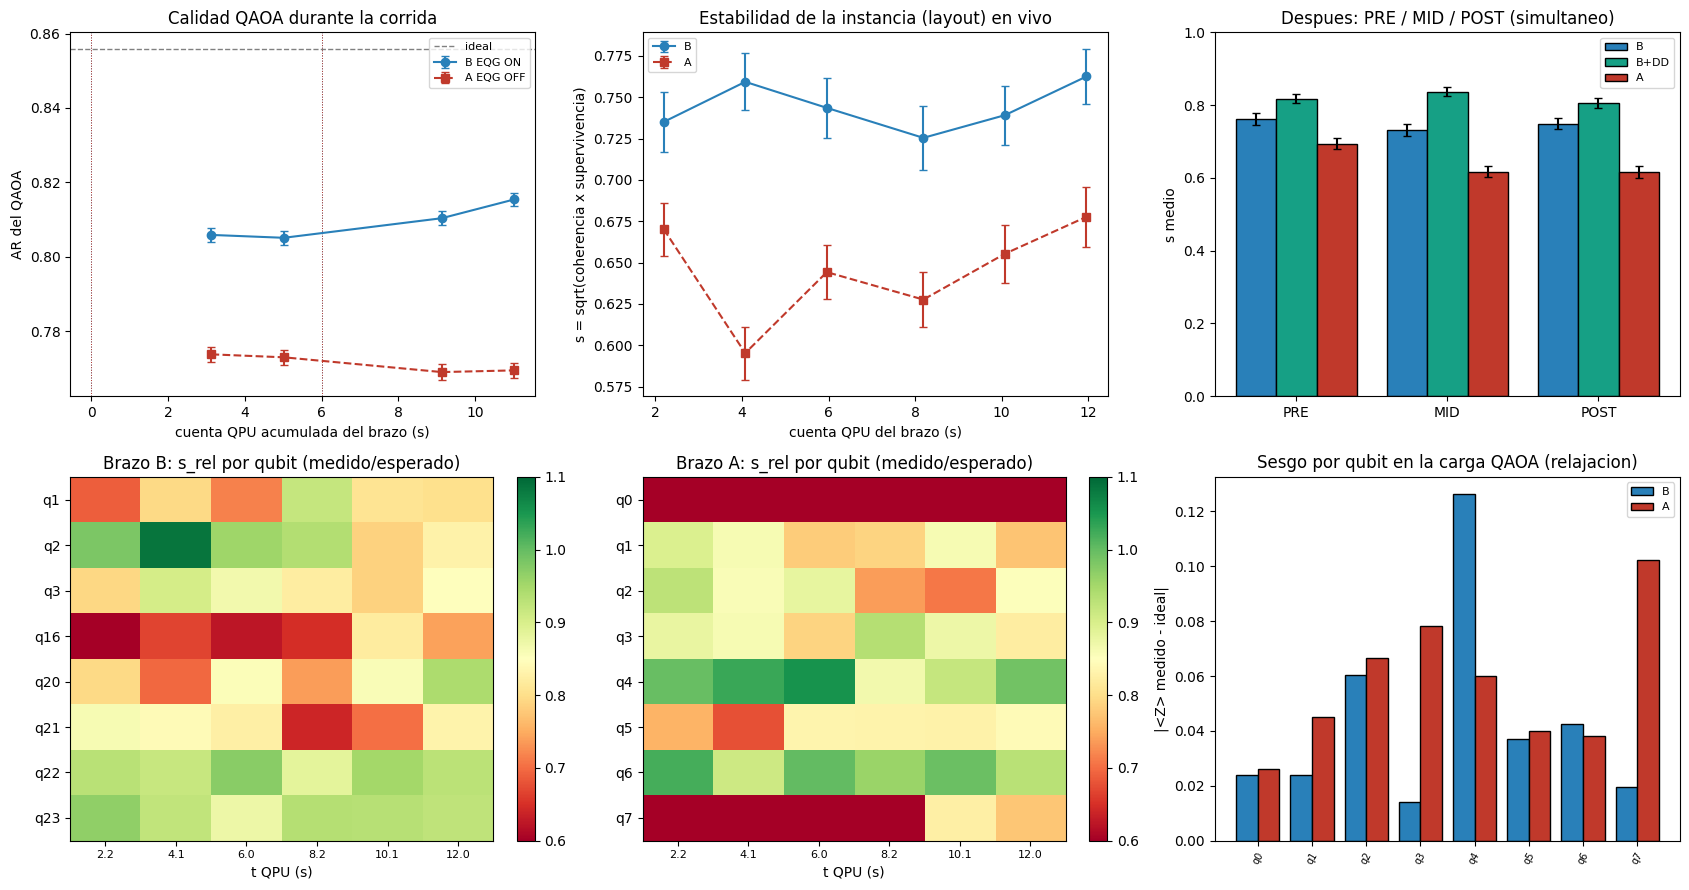

Figura: /kaggle/working/eqg_qaoa_AB/qaoa_stability.png

Validacion terminada.


In [39]:
# ============================================================
# INFORME FORMAL — veredicto, criterios, JSON y figuras
# ============================================================
verdict, notes = "INCOMPLETO", []
z_ar = None
if not stack_ok:
    verdict = "STACK_INCOMPLETO_B"; notes.append("Falto una etapa EQG en B")
elif result_A is None:
    verdict = "B_OK_A_OMITIDO"; notes.append("B integro; A no ejecutado")
else:
    d_ar = mB["ar"] - mA["ar"]; se_d = math.hypot(mB["se_ar"], mA["se_ar"]); z_ar = d_ar / se_d if se_d > 0 else 0.0
    if abs(z_ar) < Z_SIG:
        verdict = "SIN_DISTINCION_ESTADISTICA"
        notes.append("Orden experimental: A→B (invertido)"); notes.append("AR(B)-AR(A)=%+.4f +- %.4f (z=%.1f): dentro de ruido de shots" % (d_ar, se_d, z_ar))
    elif z_ar > 0:
        verdict = "EQG_MEJORA_QAOA"
        notes.append("Orden experimental: A→B (invertido)"); notes.append("AR(B)-AR(A)=%+.4f +- %.4f (z=%.1f): EQG da mejor resultado QAOA" % (d_ar, se_d, z_ar))
    else:
        verdict = "BASELINE_MEJOR"
        notes.append("Orden experimental: A→B (invertido)"); notes.append("AR(B)-AR(A)=%+.4f +- %.4f (z=%.1f): A fue mejor; revisar jobs y deriva" % (d_ar, se_d, z_ar))
    sB, sA = stab_label(mB["ar_drift"], mB["ar_drift_se"]), stab_label(mA["ar_drift"], mA["ar_drift_se"])
    notes.append("Estabilidad temporal del AR durante la corrida: B=%s (%+.4f)  A=%s (%+.4f)" % (sB, mB["ar_drift"], sA, mA["ar_drift"]))
    # atribucion: layout vs DD (medida con snapshots simultaneos)
    la = [d for d, e in layout_adv.values()]; la_sig = any(abs(d) > Z_SIG * e for d, e in layout_adv.values())
    de = [d for d, e in dd_eff.values()]; de_sig = any(abs(d) > Z_SIG * e for d, e in dd_eff.values())
    notes.append("Atribucion (snapshots simultaneos): layout MORPH vs ingenuo medio %+.3f (%s); DD on-off medio %+.3f (%s)" % (
        np.mean(la) if la else float("nan"), "significativo" if la_sig else "ruido",
        np.mean(de), "significativo" if de_sig else "ruido"))
    notes.append("Pulsos DD insertados en circuitos QAOA (B): %d" % result_B["dd"]["pulses_work"] +
                 ("  [0 = el circuito no tiene ventanas ociosas aprovechables; el efecto de EQG viene del layout]" if result_B["dd"]["pulses_work"] == 0 else ""))
    bad = [n for n, d in deltas.items() if d["sig"] and d["agg"] < 0]
    notes.append("Deriva significativa negativa entre snapshots: %s" % (bad if bad else "ninguna"))

crit = {
    "C1 stack B completo": stack_ok,
    "C2 cuenta B <= %.1f s (+%d%%)" % (BUDGET_ARM_S, round((BUDGET_TOL - 1) * 100)): result_B["account_s"] <= BUDGET_ARM_S * BUDGET_TOL,
    "C3 cuenta A <= tope y plan identico": (result_A is not None and result_A["account_s"] <= BUDGET_ARM_S * BUDGET_TOL
                                            and [w["shots"] for w in result_A["works"]] == [w["shots"] for w in result_B["works"]]),
    "C4 series AR y estabilidad en A y B": (result_A is not None and len(result_A["works"]) > 0 and len(result_B["works"]) > 0),
    "C5 snapshots PRE/MID/POST": len(snaps_ts) == 3,
    "C6 estabilidad por qubit + deriva": bool(mB["qubits"]) and (mA is None or bool(mA["qubits"])),
    "C7 veredicto con estadistica": z_ar is not None,
}

print("=" * 72 + "\nINFORME FORMAL — QAOA 15 s (A→B): EQG vs sin EQG\n" + "=" * 72)
print("MODE=%s backend=%s  QAOA N=%d p=%d  plan=%d jobs x %d lotes x %d shots" % (
    MODE, BACKEND, N_QAOA, P_LAYERS, PLAN["n_jobs"], CHUNKS_PER_JOB, PLAN["shots_chunk"]))
rows = [
    ("layout (inicio -> fin)", "%s -> %s" % (result_B["layout0"], result_B["layout_end"]), "%s" % (result_A["layout0"] if result_A else None)),
    ("plan0 / intervenciones", "%s / %d" % (result_B["plan0"]["tipo"], result_B["interventions"]), "ninguna / 0"),
    ("AR QAOA", "%.4f +- %.4f" % (mB["ar"], mB["se_ar"]), "%.4f +- %.4f" % (mA["ar"], mA["se_ar"]) if mA else None),
    ("retencion vs ideal", "%.2f" % mB["retention"], "%.2f" % mA["retention"] if mA else None),
    ("P(corte optimo)", "%.3f" % mB["p_opt"], "%.3f" % mA["p_opt"] if mA else None),
    ("deriva AR en la corrida", "%+.4f" % mB["ar_drift"], "%+.4f" % mA["ar_drift"] if mA else None),
    ("s instancia (medio)", "%.3f" % mB["inst_s_mean"], "%.3f" % mA["inst_s_mean"] if mA else None),
    ("qubits estables/degr./inest.", "%d/%d/%d" % tuple(sum(q["estado"] == e for q in mB["qubits"]) for e in ("estable", "degradado", "inestable")),
     "%d/%d/%d" % tuple(sum(q["estado"] == e for q in mA["qubits"]) for e in ("estable", "degradado", "inestable")) if mA else None),
    ("cuenta QPU (s)", "%.2f" % result_B["account_s"], "%.2f" % result_A["account_s"] if mA else None),
]
print("%-30s %-34s %-30s" % ("metrica", "B EQG ON", "A EQG OFF")); print("-" * 96)
for n, b, a in rows: print("%-30s %-34s %-30s" % (n, b, a))
print("-" * 96)
for k, v in crit.items(): print("  [%s] %s" % ("OK" if v else "NO", k))
print("\nVEREDICTO: " + verdict)
for n in notes: print("  - " + n)
print("=" * 72)

report = {"project": "EDGE Quantum Guard", "experiment": "QAOA 15 s (A→B): EQG vs sin EQG, estabilidad de instancia y qubits",
          "verdict": verdict, "notes": notes, "criteria": crit, "gate": gate, "plan": {k: v for k, v in PLAN.items() if k != "jobs"},
          "layouts": {"B": LAYOUT_B, "A": LAYOUT_A}, "ideal": IDEAL, "theta": THETA.tolist(),
          "B": result_B, "A": result_A, "metrics": {"B": mB, "A": mA},
          "snapshots": {n: s for n, s in snaps_ts}, "deltas": deltas,
          "layout_effect": layout_adv, "dd_effect": dd_eff, "cal_stamp_pre": CAL_STAMP0, "cal_changed": cal_changed,
          "jobs": _job_log, "params": {"MODE": MODE, "BUDGET_ARM_S": BUDGET_ARM_S, "OVERHEAD_CUR": OVERHEAD_CUR, "SEED": SEED}}
(OUT / "report.json").write_text(json.dumps(report, indent=2, default=str))
(OUT / "summary.txt").write_text("VEREDICTO: %s\n%s\n" % (verdict, "\n".join(notes)))
print("Guardado:", OUT / "report.json")

# ------------------------- figuras -------------------------
col = {"B": "#2980b9", "A": "#c0392b"}
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for r_, nm in ((result_B, "B"), (result_A, "A")):
    if r_ is None: continue
    W = r_["works"]
    ax[0, 0].errorbar([w["t_qpu"] for w in W], [w["ar"] for w in W], yerr=[w["se_ar"] for w in W],
                      fmt="o-" if nm == "B" else "s--", color=col[nm], capsize=3, label="%s %s" % (nm, "EQG ON" if nm == "B" else "EQG OFF"))
    for j in r_["jobs"]:
        ax[0, 0].axvline(j["t_start"], color=col[nm], ls=":", lw=0.7)
ax[0, 0].axhline(IDEAL["ar"], color="gray", ls="--", lw=1, label="ideal")
ax[0, 0].set_xlabel("cuenta QPU acumulada del brazo (s)"); ax[0, 0].set_ylabel("AR del QAOA"); ax[0, 0].set_title("Calidad QAOA durante la corrida"); ax[0, 0].legend(fontsize=8)

for r_, nm in ((result_B, "B"), (result_A, "A")):
    if r_ is None: continue
    S = r_["snaps"]
    ax[0, 1].errorbar([s["t_qpu"] for s in S], [s["mean_s"] for s in S], yerr=[s["se_mean_s"] for s in S],
                      fmt="o-" if nm == "B" else "s--", color=col[nm], capsize=3, label=nm)
ax[0, 1].set_xlabel("cuenta QPU del brazo (s)"); ax[0, 1].set_ylabel("s = sqrt(coherencia x supervivencia)")
ax[0, 1].set_title("Estabilidad de la instancia (layout) en vivo"); ax[0, 1].legend(fontsize=8)

names = [n for n, _ in snaps_ts]; vcol = {"B": col["B"], "B+DD": "#16a085", "A": col["A"]}
wd = 0.8 / max(len(snap_pre["variants"]), 1)
for k, v in enumerate(snap_pre["variants"]):
    ax[0, 2].bar(np.arange(len(names)) + k * wd, [s["variants"][v]["mean_s"] for _, s in snaps_ts], wd,
                 yerr=[s["variants"][v]["se_mean_s"] for _, s in snaps_ts], color=vcol.get(v, "gray"), edgecolor="k", capsize=3, label=v)
ax[0, 2].set_xticks(np.arange(len(names)) + wd); ax[0, 2].set_xticklabels(names)
ax[0, 2].set_ylim(min(0.5, ax[0, 2].get_ylim()[0]), 1.0); ax[0, 2].set_ylabel("s medio"); ax[0, 2].set_title("Despues: PRE / MID / POST (simultaneo)"); ax[0, 2].legend(fontsize=8)

for k, (r_, nm) in enumerate(((result_B, "B"), (result_A, "A"))):
    a_ = ax[1, k]
    if r_ is None: a_.axis("off"); continue
    qs = sorted({q for s in r_["snaps"] for q in s["layout"]})
    M = np.full((len(qs), len(r_["snaps"])), np.nan)
    for c_, s in enumerate(r_["snaps"]):
        for q, v in zip(s["layout"], s["s_rel"]): M[qs.index(q), c_] = v
    im = a_.imshow(M, aspect="auto", cmap="RdYlGn", vmin=0.6, vmax=1.1)
    a_.set_yticks(range(len(qs))); a_.set_yticklabels(["q%d" % q for q in qs]); a_.set_xticks(range(len(r_["snaps"])))
    a_.set_xticklabels(["%.1f" % s["t_qpu"] for s in r_["snaps"]], fontsize=8)
    a_.set_xlabel("t QPU (s)"); a_.set_title("Brazo %s: s_rel por qubit (medido/esperado)" % nm); plt.colorbar(im, ax=a_, fraction=0.04)

for r_, m_, nm, off in ((result_B, mB, "B", -0.2), (result_A, mA, "A", 0.2)):
    if r_ is None: continue
    ax[1, 2].bar(np.arange(len(m_["qubits"])) + off, [q["zbias_abs"] for q in m_["qubits"]], 0.4, color=col[nm], edgecolor="k", label=nm)
    ax[1, 2].set_xticks(np.arange(len(m_["qubits"]))); ax[1, 2].set_xticklabels(["q%d" % q["q"] for q in m_["qubits"]], rotation=60, fontsize=7)
ax[1, 2].set_ylabel("|<Z> medido - ideal|"); ax[1, 2].set_title("Sesgo por qubit en la carga QAOA (relajacion)"); ax[1, 2].legend(fontsize=8)
plt.tight_layout(); fig.savefig(OUT / "qaoa_stability.png", dpi=140, bbox_inches="tight"); plt.show()
print("Figura:", OUT / "qaoa_stability.png")
print("\nValidacion terminada.")


## 5. Interpretacion

| Veredicto | Significado |
|-----------|-------------|
| `EQG_MEJORA_QAOA` | El AR de B supera al de A en mas de 2 sigma (ruido de shots) |
| `SIN_DISTINCION_ESTADISTICA` | Diferencia dentro del ruido: no se puede atribuir nada a EQG con esta corrida |
| `BASELINE_MEJOR` | A fue mejor que B: revisar jobs, deriva y layout |
| `STACK_INCOMPLETO_B` / `B_OK_A_OMITIDO` | No validar: falto una etapa o no se ejecuto el baseline |

**Como leer la estabilidad**

- *Durante*: serie de AR y de `s` (coherencia x supervivencia) por snapshot en vivo; por qubit, el **jitter en exceso** (sobre el ruido de shots) y la **deriva** (pendiente x duracion). Estable = jitter <= 0.04 y deriva >= -0.05; degradado/inestable por encima de los umbrales pre-registrados.
- *Despues*: snapshots **PRE / MID / POST** miden a la vez el layout MORPH (con y sin DD) y el ingenuo. Lo que cambia entre ellos es deriva del hardware; la diferencia B - A en el mismo instante es efecto de layout; B+DD - B es efecto de DD.
- *Instancia*: estado del backend, sello de calibracion y T1/T2/lectura de los qubits usados.

**Limites honestos**

1. Los brazos corren en serie: la deriva entre ellos se controla con el snapshot MID, no se elimina. Un solo par B/A no prueba causalidad; repite la corrida o inviertela (A->B) para confirmarlo.
2. El DD solo actua en ventanas ociosas; en un QAOA corto puede insertar pocos pulsos (se reporta el conteo). El efecto dominante suele ser el layout.
3. La cuenta QPU es la que informa IBM por job (`usage`); si no esta disponible se usa una estimacion y queda marcada como `estimado`.
4. El orden de ejecucion dentro de un job se asume secuencial (el eje temporal intra-job es nominal).

**Entregables:** `report.json`, `summary.txt`, `qaoa_stability.png`.

**Orden de esta corrida: A→B**

Esta replica invierte los brazos respecto a la corrida de referencia (B→A). Si EQG vuelve a mejorar el AR con z>=2, el efecto es mas robusto al confusor de deriva temporal. Si el signo se invierte o desaparece, la deriva entre brazos puede estar dominando y hace falta mas replicas.
